<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">DISSIPATIVE PARTICLE DYNAMICS · NOTEBOOK 1 OF 4</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">A DPD fluid<br>from scratch</h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">A small dissipative particle dynamics (DPD) code is written in NumPy, from the three pair forces to the Groot–Warren integrator, and checked against the standard DPD fluid of Groot and Warren: temperature control against the time step, the equation of state, the radial distribution function and diffusion.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">Fluid: ρ = 3, a = 25, γ = 4.5, Δt = 0.04 τ, 1536 beads · equation of state: ρ from 1 to 8, a = 15, 25 and 30 · programs: NumPy, SciPy</p>
</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The notebook answers four questions:

1. How well does the DPD thermostat hold k<sub>B</sub>T = 1, and how does the time step change this?
2. What is the equation of state of the DPD fluid, and which repulsion gives the compressibility of water?
3. What does the structure of a DPD fluid, its radial distribution function g(r), look like?
4. How fast do the beads diffuse, against the estimate of Groot and Warren?

The theory follows the papers of Hoogerbrugge and Koelman [1], Español and Warren [2] and Groot and Warren [3], and
chapter 3 of [4]. Equations and figures of [3] are cited by their numbers in that paper. Three exercises with
solutions test the fluctuation–dissipation theorem, the friction and the compressibility. A full run takes about
five minutes on a laptop or on the Colab CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kourosh-h/dpd-teaching/blob/main/notebooks/01_dpd_fluid.ipynb)

Folders: `figures/` (every plot of the notebook as a PDF file, written when the notebook runs).

<p>Sections: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">background</span> <span style="background-color:#3D5A80; color:#ffffff; padding:2px 9px; border-radius:10px;">model</span> <span style="background-color:#9C4F6E; color:#ffffff; padding:2px 9px; border-radius:10px;">code</span> <span style="background-color:#4F772D; color:#ffffff; padding:2px 9px; border-radius:10px;">fluid</span> <span style="background-color:#6B5B95; color:#ffffff; padding:2px 9px; border-radius:10px;">time step</span> <span style="background-color:#8C2F39; color:#ffffff; padding:2px 9px; border-radius:10px;">equation of state</span> <span style="background-color:#795548; color:#ffffff; padding:2px 9px; border-radius:10px;">structure</span> <span style="background-color:#005F73; color:#ffffff; padding:2px 9px; border-radius:10px;">diffusion</span> <span style="background-color:#6D597A; color:#ffffff; padding:2px 9px; border-radius:10px;">exercises</span> <span style="background-color:#37474F; color:#ffffff; padding:2px 9px; border-radius:10px;">summary</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">references</span></p>

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code installs the packages that are missing: NumPy, SciPy, pandas, Matplotlib, and ASE with py3Dmol for the 3D views. After an install, a restart of the kernel may be needed.</div>

In [ ]:
# Installs the packages of this notebook that are missing (on the laptop and on Colab).
# If it installs something and a later import still fails, restart the kernel and run the notebook again.
import importlib
import importlib.util
import subprocess
import sys

PACKAGES = {  # module name: pip package
    'numpy': 'numpy',
    'scipy': 'scipy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'ase': 'ase',
    'py3Dmol': 'py3Dmol',
}
missing = [package for module, package in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=True)
    importlib.invalidate_caches()
else:
    print("all packages are installed")

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">Background<br><span style="font-size:0.72em; font-weight:normal;">coarse-grained beads, reduced units and where DPD comes from</span></h2>

Atomistic molecular dynamics (MD) resolves every atom. It gives chemical detail, but typical runs cover tens of
nanometers and hundreds of nanoseconds. Many questions of soft matter lie above these scales: a polymer coating that
forms from micelles in water involves thousands of chains and microseconds. **Coarse-grained** models group several
atoms or molecules into one particle, a **bead**, and give up detail below the size of a bead. In the coating models
of [4], one polymer bead stands for about 5 monomers and one water bead for 33 water molecules.

**Dissipative particle dynamics** (DPD) is a coarse-grained method for fluids. Hoogerbrugge and Koelman [1]
introduced it in 1992 to simulate hydrodynamics with particles that move in continuous space: the speed of
lattice-gas automata, without the lattice that breaks isotropy and Galilean invariance. Their particles exchanged
momentum in pairs, with a random part and a damping part, and the pairwise exchange conserved momentum, so that flow
behaved as in the Navier–Stokes equations. Español and Warren [2] wrote the method as stochastic differential
equations and showed which relation between the random and the damping forces gives the canonical ensemble (the
fluctuation–dissipation theorem below). Groot and Warren [3] then gave DPD the form in use today: an integrator for
large time steps, a repulsion fitted to the compressibility of water, and a link between the repulsion between
different beads and the Flory–Huggins parameter χ (notebook 02).

Some basic terms used below:

- **Cutoff r<sub>C</sub>**: the range of all DPD forces; it is the unit of length, r<sub>C</sub> = 1.
- **Reduced units**: lengths in r<sub>C</sub>, masses in the bead mass m, energies in k<sub>B</sub>T, where
  k<sub>B</sub> is the Boltzmann constant and T the temperature. The unit of time follows,
  τ = r<sub>C</sub>(m/k<sub>B</sub>T)<sup>1/2</sup>. All numbers in the code are reduced.
- **Number density ρ**: beads per r<sub>C</sub>³.
- **Thermostat**: forces that keep the temperature at its set value; in DPD these are the dissipative and random
  forces.
- **Canonical ensemble**: constant number of beads N, volume V and temperature T (NVT); its configurations follow the
  Boltzmann distribution exp(−U/k<sub>B</sub>T), where U is the potential energy.
- **Hydrodynamics**: the collective flow of a fluid. A thermostat that conserves momentum, as the pairwise DPD forces
  do, keeps it; a thermostat that acts on every bead alone, as in Brownian or Langevin dynamics, gives only diffusion
  [2].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#3D5A80; color:#ffffff; padding:8px 14px; border-radius:6px;">The DPD model<br><span style="font-size:0.72em; font-weight:normal;">the conservative, dissipative and random forces and the fluctuation–dissipation theorem</span></h2>

The total force on bead i is a sum over all neighbors j within the cutoff (Eq. 2 of [3]),

$$\mathbf{f}_i = \sum_{j \neq i} \left( \mathbf{F}^C_{ij} + \mathbf{F}^D_{ij} + \mathbf{F}^R_{ij} \right),$$

and the beads move by Newton's equations, dr<sub>i</sub>/dt = v<sub>i</sub> and dv<sub>i</sub>/dt = f<sub>i</sub>, with
m = 1. The conservative force is a soft repulsion that gives each bead type its chemical character (Eq. 3 of [3]),

$$\mathbf{F}^C_{ij} = a_{ij}\,(1 - r_{ij})\,\hat{\mathbf{r}}_{ij} \quad (r_{ij} < 1), \qquad \mathbf{F}^C_{ij} = 0 \quad (r_{ij} \geq 1),$$

where a<sub>ij</sub> is the largest repulsion between beads i and j, r<sub>ij</sub> = |r<sub>i</sub> − r<sub>j</sub>| their
distance and r̂<sub>ij</sub> = (r<sub>i</sub> − r<sub>j</sub>)/r<sub>ij</sub> the unit vector from j to i. The
dissipative force is a friction on the relative motion of the pair, and the random force a kick of random size (Eq. 4
of [3]),

$$\mathbf{F}^D_{ij} = -\gamma\, w^D(r_{ij})\,(\hat{\mathbf{r}}_{ij}\cdot\mathbf{v}_{ij})\,\hat{\mathbf{r}}_{ij}, \qquad \mathbf{F}^R_{ij} = \zeta\, w^R(r_{ij})\,\theta_{ij}\,\hat{\mathbf{r}}_{ij},$$

where γ is the friction coefficient, ζ the noise amplitude (σ in [3]), v<sub>ij</sub> = v<sub>i</sub> − v<sub>j</sub>,
w<sup>D</sup> and w<sup>R</sup> are weight functions that vanish beyond r<sub>C</sub>, and θ<sub>ij</sub> = θ<sub>ji</sub>
is a random variable with zero mean and unit variance, drawn independently for every pair at every step. All three
forces act along the line between the two beads and are equal and opposite on i and j, so they conserve linear and
angular momentum.

The friction removes energy and the noise puts it back. Español and Warren [2] showed that the system samples the
canonical ensemble at temperature T only if the two are balanced, by the **fluctuation–dissipation theorem** (Eq. 5 of
[3]):

$$w^D(r) = \left[w^R(r)\right]^2, \qquad \zeta^2 = 2\gamma k_BT .$$

One weight function can be chosen freely and fixes the other. The usual choice, also in [3, 4], is w<sup>R</sup>(r)
= 1 − r for r < 1 (Eq. 6 of [3]). Groot and Warren used ζ = 3, which gives γ = 4.5 at k<sub>B</sub>T = 1; the
coating models of [4] use the same γ. Hoogerbrugge and Koelman [1] had used the same weight function for both forces;
Exercise 1 shows what that does.

With a time step Δt, the random force of one step is ζ w<sup>R</sup> θ<sub>ij</sub> Δt<sup>−1/2</sup> r̂<sub>ij</sub>
(Eq. 8 of [3]). The factor Δt<sup>−1/2</sup> keeps the diffusion over a fixed time independent of the step: the
momentum that random kicks add over a time t is a sum of t/Δt independent terms, so its variance grows with
(t/Δt) × variance of one kick × Δt², which stays finite and proportional to t only if the variance of one kick is
proportional to 1/Δt (Eq. 10 of [3]).

Integrating F<sup>C</sup> gives the pair energy U(r) = (a/2)(1 − r)². At full overlap (r = 0) it is only
12.5 k<sub>B</sub>T for a = 25, so two beads can sit on top of each other; a Lennard-Jones pair at the same distance
has an infinite energy. This softness allows a time step about 20 to 40 times larger than in atomistic MD.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code imports the packages and sets the time step, the friction, the folders, colors and plot settings.</div>

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import quad
from scipy.spatial import cKDTree

DT = 0.04          # time step (tau), the value Groot and Warren recommend
GAMMA = 4.5        # friction coefficient gamma; with k_BT = 1 the noise amplitude is zeta = sqrt(2 gamma) = 3

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

# colors of the bead types: A hydrophilic or minority block, B hydrophobic or majority block, B19 hydrophobic
# homopolymer, C substrate, D water; ink: the single-component fluid and the model lines
C = {'A': '#0C54B4', 'B': '#B7371B', 'B19': '#E4840C', 'C': '#795548', 'D': '#2CA02C', 'ink': '#282B28'}

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'pdf.fonttype': 42,
                     'mathtext.default': 'it', 'axes.unicode_minus': False, 'font.size': 10.0,
                     'axes.labelsize': 10.0, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9.0,
                     'axes.linewidth': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelpad': 2.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.major.size': 4.2, 'ytick.major.size': 4.2, 'xtick.major.width': 1.0,
                     'ytick.major.width': 1.0, 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,
                     'xtick.minor.width': 0.7, 'ytick.minor.width': 0.7, 'xtick.minor.visible': True,
                     'ytick.minor.visible': True, 'xtick.major.pad': 3.0, 'ytick.major.pad': 3.0,
                     'lines.linewidth': 1.45, 'lines.markersize': 4.25, 'lines.dashed_pattern': [4.0, 2.2],
                     'lines.scale_dashes': False, 'legend.frameon': False, 'legend.handlelength': 1.8,
                     'legend.handletextpad': 0.4, 'legend.columnspacing': 1.6, 'savefig.dpi': 300})


def two_panels(height=2.6):
    """
    Figure 7.0 inches wide with two panels side by side, (a) and (b), 1.61 inches high; a figure higher than 2.6
    inches has more room above the panels, for a legend of two rows.
    """
    fig = plt.figure(figsize=(7.0, height))
    left = fig.add_axes([0.085, 0.429 / height, 0.385, 1.612 / height])
    right = fig.add_axes([0.595, 0.429 / height, 0.385, 1.612 / height])
    left.text(-0.2, 1.03, '(a)', transform=left.transAxes, fontsize=11.0, va='bottom')
    right.text(-0.2, 1.03, '(b)', transform=right.transAxes, fontsize=11.0, va='bottom')
    return fig, left, right


def top_legend(fig, entries):
    """The legend entries in one row at the top of a figure."""
    fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(entries))


def one_panel(height=2.6, left=0.085):
    """Figure 7.0 inches wide with one panel, 1.61 inches high, at the same height as the panels of two_panels."""
    fig = plt.figure(figsize=(7.0, height))
    axes = fig.add_axes([left, 0.429 / height, 0.98 - left, 1.612 / height])
    return fig, axes


def panel_title(axes, text):
    """A short label at the top center of a panel: the name of what it shows."""
    axes.text(0.5, 1.02, text, transform=axes.transAxes, ha='center', va='bottom')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 1.** (a) Pair energy of DPD with a = 25 against a Lennard-Jones potential with its minimum at r = 1;
(b) the weight functions of the random and the dissipative forces. `figures/potentials.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 1 (<code>figures/potentials.pdf</code>); the table gives the DPD pair energy and the two weight functions at three distances.</div>

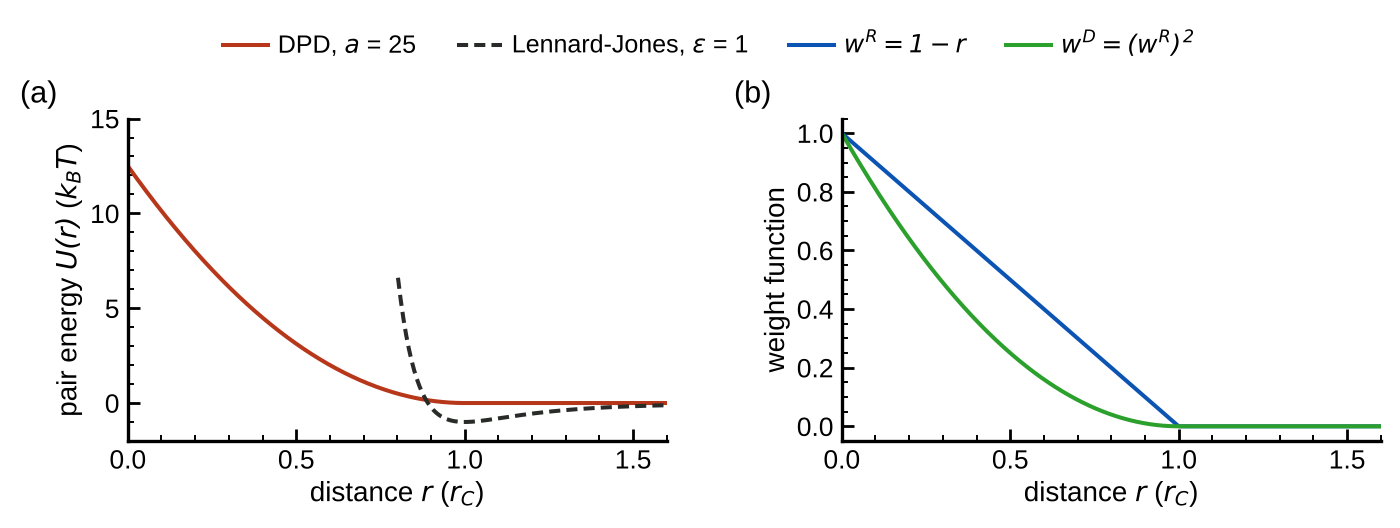

,"U, DPD (k_BT)",w^R,w^D
r (r_C),,,
0.0,12.500,1.0,1.00
0.5,3.125,0.5,0.25
1.0,0.000,0.0,0.00


In [3]:
r = np.linspace(0.0, 1.6, 400)
a = 25.0
u_dpd = np.where(r < 1, 0.5 * a * (1 - r)**2, 0.0)
sigma_lj = 2**(-1 / 6)                     # Lennard-Jones sigma that puts the minimum at r = 1
r_lj = r[r > 0.8]
u_lj = 4 * ((sigma_lj / r_lj)**12 - (sigma_lj / r_lj)**6)
w_r = np.where(r < 1, 1 - r, 0.0)

fig, left, right = two_panels()
left.plot(r, u_dpd, color=C['B'])
left.plot(r_lj, u_lj, color=C['ink'], ls='--')
left.set_xlim(0, 1.6)
left.set_ylim(-2, 15)
left.set_xlabel(r'distance $r$ ($r_C$)')
left.set_ylabel(r'pair energy $U(r)$ ($k_BT$)')
right.plot(r, w_r, color=C['A'])
right.plot(r, w_r**2, color=C['D'])
right.set_xlim(0, 1.6)
right.set_xlabel(r'distance $r$ ($r_C$)')
right.set_ylabel('weight function')
top_legend(fig, [Line2D([], [], color=C['B'], label='DPD, $a$ = 25'),
                 Line2D([], [], color=C['ink'], ls='--', label='Lennard-Jones, $\\varepsilon$ = 1'),
                 Line2D([], [], color=C['A'], label='$w^R = 1 - r$'),
                 Line2D([], [], color=C['D'], label='$w^D = (w^R)^2$')])
fig.savefig(FIGURES / 'potentials.pdf')
plt.show()

distances = [0.0, 0.5, 1.0]
pd.DataFrame({'U, DPD (k_BT)': [0.5 * a * (1 - x)**2 for x in distances], 'w^R': [1 - x for x in distances],
              'w^D': [(1 - x)**2 for x in distances]}, index=pd.Index(distances, name='r (r_C)'))

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#9C4F6E; color:#ffffff; padding:8px 14px; border-radius:6px;">The DPD code<br><span style="font-size:0.72em; font-weight:normal;">neighbor search, forces and the Groot–Warren integrator</span></h2>

Every force is zero beyond r<sub>C</sub> = 1, so only pairs closer than 1 are needed. A loop over all N² pairs in
Python is too slow; a k-d tree of SciPy finds the pairs, and its `boxsize` option handles the **periodic boundary
conditions**: the box is repeated in all directions, so that a bead that leaves on one side comes back on the other and
there are no walls. The pair vectors follow the **minimum image convention**: if two beads are more than half a box
apart along an axis, the nearest copy of j is in the neighboring image, and the vector is shifted by one box length
[5].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>find_pairs</code>, which returns the pairs closer than r<sub>C</sub> and their minimum image vectors.</div>

In [4]:
def find_pairs(pos, box):
    """Pairs closer than r_C = 1 (index arrays i < j) and their minimum image vectors r_i - r_j."""
    wrapped = pos % box
    pairs = cKDTree(wrapped, boxsize=box).query_pairs(1.0, output_type='ndarray')
    i, j = pairs[:, 0], pairs[:, 1]
    rij = wrapped[i] - wrapped[j]
    rij -= box * np.round(rij / box)                 # minimum image convention
    return i, j, rij

<div style="box-sizing:border-box; width:calc(100% - 40px);">

Each pair appears once in `(i, j)`, so the pair force is added to bead i and subtracted from bead j (Newton's third
law); `np.bincount` does this sum for all pairs at once. The bead types are integers and `a` is a matrix, so
`a[types[i], types[j]]` picks the repulsion of every pair; for one bead type, `a` is a 1 × 1 matrix. The random numbers
are Gaussian here; Groot and Warren [3] found no difference with uniform random numbers of the same variance.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>dpd_forces</code>, the sum of the conservative, dissipative and random pair forces on every bead.</div>

In [5]:
def dpd_forces(pos, vel, types, a, box, rng, gamma=GAMMA, kT=1.0, dt=DT, wd_power=2):
    """
    Conservative + dissipative + random pair force on every bead. a is the repulsion matrix of the bead types;
    w^D = (w^R)**wd_power, and wd_power = 2 is the choice that satisfies the fluctuation-dissipation theorem.
    """
    count = len(pos)
    i, j, rij = find_pairs(pos, box)
    r = np.linalg.norm(rij, axis=1)
    unit = rij / r[:, None]                          # unit vector from j to i
    weight = 1.0 - r                                 # w^R(r)
    vij = vel[i] - vel[j]
    zeta = np.sqrt(2.0 * gamma * kT)                 # zeta^2 = 2 gamma k_BT

    conservative = a[types[i], types[j]] * weight
    dissipative = -gamma * weight**wd_power * np.sum(unit * vij, axis=1)
    random = zeta * weight * rng.standard_normal(len(r)) / np.sqrt(dt)
    pair_force = (conservative + dissipative + random)[:, None] * unit

    force = np.zeros((count, 3))
    for axis in range(3):                            # +F on bead i and -F on bead j (Newton's third law)
        force[:, axis] = np.bincount(i, pair_force[:, axis], count) - np.bincount(j, pair_force[:, axis], count)
    return force

<div style="box-sizing:border-box; width:calc(100% - 40px);">

Hoogerbrugge and Koelman [1] and Español and Warren [2] moved the beads with an Euler-type scheme (Eq. 7 of [3]). The
dissipative force depends on the velocities, so a velocity-Verlet scheme needs the velocity at t + Δt to compute the
force at t + Δt. Groot and Warren [3] use a predicted velocity (Eq. 9 of [3]):

$$\mathbf{r}_i(t+\Delta t) = \mathbf{r}_i(t) + \Delta t\,\mathbf{v}_i(t) + \tfrac{1}{2}\Delta t^2\,\mathbf{f}_i(t)$$
$$\tilde{\mathbf{v}}_i(t+\Delta t) = \mathbf{v}_i(t) + \lambda\,\Delta t\,\mathbf{f}_i(t)$$
$$\mathbf{f}_i(t+\Delta t) = \mathbf{f}_i\big(\mathbf{r}(t+\Delta t), \tilde{\mathbf{v}}(t+\Delta t)\big)$$
$$\mathbf{v}_i(t+\Delta t) = \mathbf{v}_i(t) + \tfrac{1}{2}\Delta t\,\big(\mathbf{f}_i(t) + \mathbf{f}_i(t+\Delta t)\big)$$

If the force did not depend on the velocity, λ = 1/2 would give the plain velocity-Verlet scheme. λ is an empirical
factor; λ = 1/2 is the usual choice, and λ = 0.65 gave the best temperature control at ρ = 3 in [3]. The force is
computed once per step. The positions are kept **unwrapped**, so that a bead that leaves the box keeps counting its
distance, as the mean squared displacement needs; `find_pairs` wraps a copy of them into the box.

Two quantities are measured during the runs. The **temperature** follows from equipartition,
(3/2) k<sub>B</sub>T = (1/2) m⟨v²⟩ per bead (Eq. 13 of [3]), so with m = 1 it is the mean of v² over all components.
The **pressure** follows from the virial theorem (Eq. 15 of [3]),

$$p = \rho k_BT + \frac{1}{3V}\Big\langle \sum_{i<j} \mathbf{r}_{ij}\cdot\mathbf{F}^C_{ij} \Big\rangle ,$$

where V is the volume of the box. Only the conservative force enters; with the correct Boltzmann distribution the
dissipative and random forces add nothing on average [3].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>run</code>, the Groot–Warren integrator, and the helpers <code>random_box</code>, <code>temperature</code> and <code>pressure</code>.</div>

In [6]:
def run(pos, vel, types, a, box, nsteps, dt=DT, lam=0.5, gamma=GAMMA, kT=1.0, wd_power=2, seed=0, every=100,
        callback=None):
    """Groot-Warren modified velocity Verlet; positions stay unwrapped; callback(step, pos, vel) every few steps."""
    rng = np.random.default_rng(seed)
    pos, vel = pos.copy(), vel.copy()
    force = dpd_forces(pos, vel, types, a, box, rng, gamma, kT, dt, wd_power)
    for step in range(1, nsteps + 1):
        pos += dt * vel + 0.5 * dt**2 * force
        predicted = vel + lam * dt * force
        new_force = dpd_forces(pos, predicted, types, a, box, rng, gamma, kT, dt, wd_power)
        vel += 0.5 * dt * (force + new_force)
        force = new_force
        if callback is not None and step % every == 0:
            callback(step, pos, vel)
    return pos, vel


def random_box(count, box, rng):
    """Random positions in the box and Gaussian velocities (k_BT = 1) with zero total momentum."""
    pos = rng.random((count, 3)) * box
    vel = rng.standard_normal((count, 3))
    return pos, vel - vel.mean(axis=0)


def temperature(vel):
    """k_BT from equipartition, m <v_x^2> with m = 1."""
    return np.mean(vel**2)


def pressure(pos, vel, types, a, box):
    """Virial pressure (k_BT / r_C^3) from the kinetic energy and the conservative forces."""
    i, j, rij = find_pairs(pos, box)
    r = np.linalg.norm(rij, axis=1)
    virial = np.sum(a[types[i], types[j]] * (1.0 - r) * r)
    return (np.sum(vel**2) + virial) / (3.0 * np.prod(box))

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>show_3d</code>, which shows a configuration or a trajectory in 3D (drag to rotate, scroll to zoom); the viewers show only while the notebook runs.</div>

In [7]:
# py3Dmol runs on Colab and in Jupyter on the Mac with no widget setup (nglview needs extra setup on Colab)
import py3Dmol
from ase import Atoms


def show_3d(frames, colors, every=1, radius=0.35, width=640, height=420, interval_ms=120):
    """
    Shows one ASE Atoms object, or a list of them (every n-th frame) as a looping movie, with the box edges. The
    bead types are stored as chemical symbols; colors maps each symbol to a color, and symbols not in it are hidden.
    """
    if not isinstance(frames, list):
        frames = [frames]
    frames = frames[::every]
    text = ""
    for frame in frames:  # xyz text with two decimals, which keeps the saved notebook small
        shown = [index for index, symbol in enumerate(frame.get_chemical_symbols()) if symbol in colors]
        text += f"{len(shown)}\n\n"
        for index in shown:
            x, y, z = frame.positions[index]
            text += f"{frame.get_chemical_symbols()[index]} {x:.2f} {y:.2f} {z:.2f}\n"
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames(text, "xyz")
    for symbol, color in colors.items():
        view.setStyle({"elem": symbol}, {"sphere": {"radius": radius, "color": color}})
    corners = [i * frames[0].cell[0] + j * frames[0].cell[1] + k * frames[0].cell[2]
               for i in (0, 1) for j in (0, 1) for k in (0, 1)]
    for first in range(8):
        for second in range(first + 1, 8):
            if bin(first ^ second).count("1") == 1:  # corners that differ in one direction share an edge
                start = dict(zip("xyz", map(float, corners[first])))
                end = dict(zip("xyz", map(float, corners[second])))
                view.addLine({"start": start, "end": end, "color": "gray"})
    if len(frames) > 1:
        view.animate({"loop": "forward", "interval": interval_ms})
    view.zoomTo()
    view.show()

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#4F772D; color:#ffffff; padding:8px 14px; border-radius:6px;">The standard DPD fluid<br><span style="font-size:0.72em; font-weight:normal;">temperature and pressure at ρ = 3 and a = 25</span></h2>

The standard DPD fluid has the density ρ = 3 and the repulsion a = 25 between all beads. Groot and Warren [3] chose
these values so that the compressibility of the DPD fluid matches that of water at room temperature (see the equation
of state below); the coating models of [4, 6, 7] use them for every bead type. A box of 8 × 8 × 8 r<sub>C</sub>³ at
ρ = 3 holds 1536 beads, which start at random positions; the soft repulsion allows this start, which would explode
with a Lennard-Jones potential. The run has 3000 steps of Δt = 0.04 τ (120 τ), the time step that [3] recommends; the
coating studies of [4] used Δt = 0.05 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code places 1536 beads at random in the box and runs 3000 steps, recording the temperature and the pressure every 10 steps and the positions every 150 steps.</div>

In [8]:
rho = 3.0
box = np.array([8.0, 8.0, 8.0])
count = int(rho * np.prod(box))
types = np.zeros(count, dtype=int)
a = np.array([[25.0]])
pos0, vel0 = random_box(count, box, np.random.default_rng(1))

log = {'time': [], 'kT': [], 'p': []}
frames = [pos0 % box]                                # positions every 150 steps, for the 3D movie


def record(step, pos, vel):
    log['time'].append(step * DT)
    log['kT'].append(temperature(vel))
    log['p'].append(pressure(pos, vel, types, a, box))
    if step % 150 == 0:
        frames.append(pos % box)


start = time.time()
pos, vel = run(pos0, vel0, types, a, box, nsteps=3000, every=10, callback=record, seed=2)
print(f'{count} beads, 3000 steps in {time.time() - start:.0f} s')

1536 beads, 3000 steps in 16 s


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 1.** The 1536 beads at their random start, in the 8 × 8 × 8 r<sub>C</sub>³ box.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the start configuration in 3D (Viewer 1).</div>

In [ ]:
show_3d(Atoms(['C'] * count, positions=pos0, cell=box), {'C': C['A']}, radius=0.3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 2.** The first 120 τ of the run, one frame every 6 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code plays the run as a 3D movie (Viewer 2).</div>

In [ ]:
movie = [Atoms(['C'] * count, positions=x, cell=box) for x in frames]
show_3d(movie, {'C': C['A']}, radius=0.3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 2.** The DPD fluid from a random start: (a) temperature, (b) pressure against time. The dashed lines mark
k<sub>B</sub>T = 1 and the Groot–Warren pressure p = ρk<sub>B</sub>T + αaρ² with α = 0.101 (Eq. 16 of [3]).
`figures/temperature_pressure.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 2 (<code>figures/temperature_pressure.pdf</code>); the table gives the mean and the standard deviation (over the recorded steps) after the first 20 τ.</div>

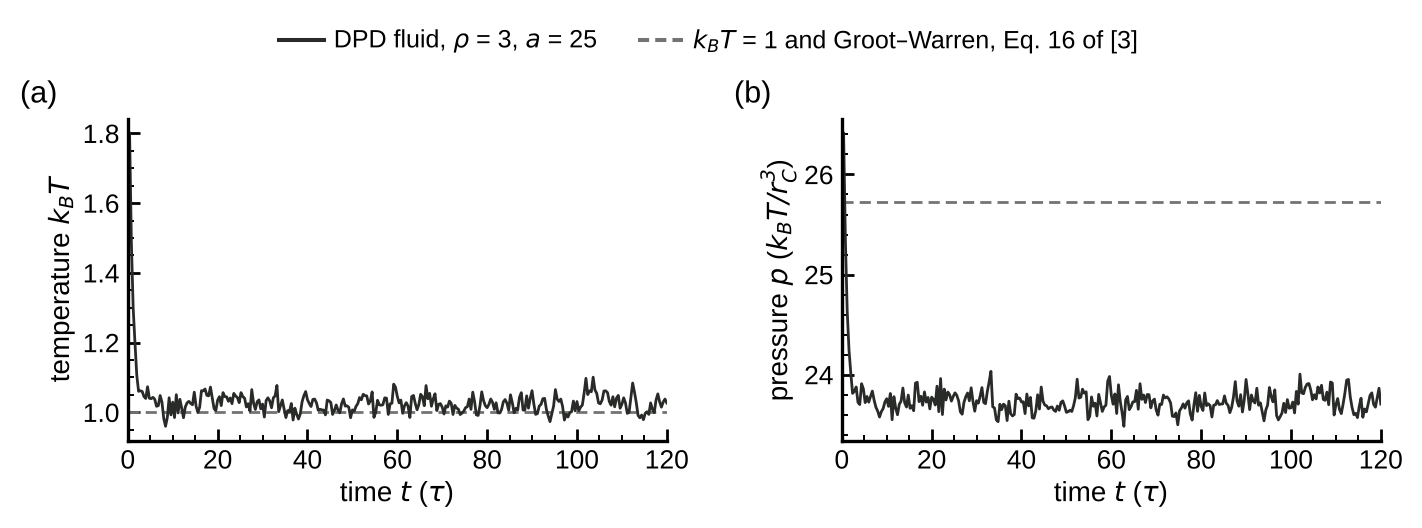

,mean after 20 τ,standard deviation,target or Groot–Warren
k_BT,1.025,0.023,1.000
pressure (k_BT/r_C³),23.726,0.101,25.725


In [11]:
times, kT, p = np.array(log['time']), np.array(log['kT']), np.array(log['p'])
late = times > 20
p_groot_warren = rho + 0.101 * 25 * rho**2

fig, left, right = two_panels()
left.axhline(1.0, color='0.45', lw=1.0, ls='--')
left.plot(times, kT, color=C['ink'], lw=1.0)
left.set_xlim(0, times[-1])
left.set_xlabel(r'time $t$ ($\tau$)')
left.set_ylabel(r'temperature $k_BT$')
right.axhline(p_groot_warren, color='0.45', lw=1.0, ls='--')
right.plot(times, p, color=C['ink'], lw=1.0)
right.set_xlim(0, times[-1])
right.set_xlabel(r'time $t$ ($\tau$)')
right.set_ylabel(r'pressure $p$ ($k_BT/r_C^3$)')
top_legend(fig, [Line2D([], [], color=C['ink'], label='DPD fluid, $\\rho$ = 3, $a$ = 25'),
                 Line2D([], [], color='0.45', ls='--', label='$k_BT$ = 1 and Groot–Warren, Eq. 16 of [3]')])
fig.savefig(FIGURES / 'temperature_pressure.pdf')
plt.show()

pd.DataFrame({'mean after 20 τ': [kT[late].mean(), p[late].mean()],
              'standard deviation': [kT[late].std(), p[late].std()],
              'target or Groot–Warren': [1.0, p_groot_warren]},
             index=['k_BT', 'pressure (k_BT/r_C³)']).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Temperature (Figure 2).** The thermostat brings the random start to k<sub>B</sub>T ≈ 1 within a few τ; after
  20 τ the mean is 1.025, 2.5 % above 1, an effect of the finite time step (next section).
- **Pressure.** The mean pressure is 23.7, against 25.7 from Eq. 16 of [3]. Eq. 16 is a fit that holds for
  ρ > 2, where the excess pressure divided by aρ² levels off; at ρ = 3 it is still slightly below the level of
  0.101, so the pressure here is 8 % lower (Figure 4).

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6B5B95; color:#ffffff; padding:8px 14px; border-radius:6px;">Time step and temperature<br><span style="font-size:0.72em; font-weight:normal;">the Euler scheme against the Groot–Warren integrator, Fig. 1 of [3]</span></h2>

Groot and Warren [3] measured the temperature as a function of Δt for the fluid with ρ = 4, a = 25 and ζ = 3 (their
Fig. 1). The thermostat holds the set temperature only in the limit Δt → 0; with a finite step, the energy that the
friction takes out and the noise puts in no longer balance exactly, and the measured temperature rises. Español and
Warren [2] saw the same effect in the original scheme: with the parameters of Hoogerbrugge and Koelman the temperature
was about 25 % above its set value. Their Fig. 1 is redone here with 1372 beads in a 7 × 7 × 7 r<sub>C</sub>³ box: each
run starts from the same equilibrated configuration and averages k<sub>B</sub>T over 300 steps after 100 steps (Groot
and Warren averaged over 200 steps of 4000 beads). The Euler scheme runs only up to Δt = 0.04 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the Euler scheme and <code>steady_temperature</code>, and measures k<sub>B</sub>T for seven time steps with the Euler scheme and the Groot–Warren integrator.</div>

In [12]:
def euler_run(pos, vel, types, a, box, nsteps, dt, gamma=GAMMA, seed=0, every=10, callback=None):
    """The Euler-type scheme of Eq. 7 of [3]: new positions and velocities from the old ones, then new forces."""
    rng = np.random.default_rng(seed)
    pos, vel = pos.copy(), vel.copy()
    force = dpd_forces(pos, vel, types, a, box, rng, gamma, 1.0, dt)
    for step in range(1, nsteps + 1):
        pos += dt * vel
        vel += dt * force
        force = dpd_forces(pos, vel, types, a, box, rng, gamma, 1.0, dt)
        if callback is not None and step % every == 0:
            callback(step, pos, vel)
    return pos, vel


# the fluid of Fig. 1 of [3]: rho = 4, a = 25, zeta = 3; 1372 beads in a 7 x 7 x 7 box
box4 = np.array([7.0, 7.0, 7.0])
count4 = int(4.0 * np.prod(box4))
types4 = np.zeros(count4, dtype=int)
pos4, vel4 = random_box(count4, box4, np.random.default_rng(3))
pos4, vel4 = run(pos4, vel4, types4, a, box4, 300, dt=0.02, seed=4)     # equilibration with a small time step


def steady_temperature(method, dt, lam=0.5, nsteps=400, discard=100):
    """Mean k_BT over the last nsteps - discard steps of a run with the Euler or the Groot-Warren scheme."""
    values = []

    def collect(step, pos, vel):
        if step > discard:
            values.append(temperature(vel))

    if method == 'euler':
        euler_run(pos4, vel4, types4, a, box4, nsteps, dt, every=5, callback=collect, seed=5)
    else:
        run(pos4, vel4, types4, a, box4, nsteps, dt=dt, lam=lam, every=5, callback=collect, seed=5)
    return np.mean(values)


steps = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07]
start = time.time()
scan = pd.DataFrame(index=pd.Index(steps, name='Δt (τ)'))
scan['Euler'] = [steady_temperature('euler', dt) if dt <= 0.04 else np.nan for dt in steps]
scan['velocity Verlet, λ = 0.5'] = [steady_temperature('verlet', dt) for dt in steps]
scan['velocity Verlet, λ = 0.65'] = [steady_temperature('verlet', dt, lam=0.65) for dt in steps]
print(f'{3 * len(steps) - 3} runs of {count4} beads in {time.time() - start:.0f} s')

18 runs of 1372 beads in 36 s


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 3.** Temperature of the DPD fluid (ρ = 4, a = 25, ζ = 3) against the time step: (a) the Euler scheme of
Eq. 7 of [3] and the Groot–Warren integrator (Eq. 9 of [3]) with λ = 0.5 and 0.65; (b) the Groot–Warren integrator
on a finer scale. The dashed line marks the set temperature.
`figures/temperature_time_step.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 3 (<code>figures/temperature_time_step.pdf</code>); the table gives the mean k<sub>B</sub>T of every run.</div>

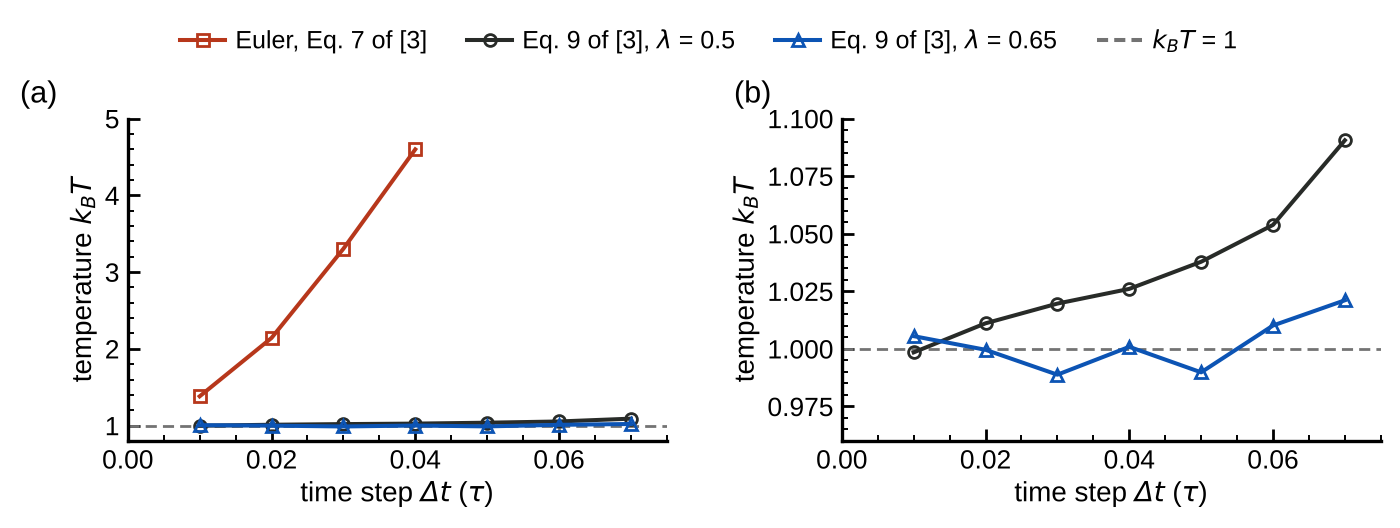

,Euler,"velocity Verlet, λ = 0.5","velocity Verlet, λ = 0.65"
Δt (τ),,,
0.01,1.382,0.998,1.006
0.02,2.142,1.011,1.000
0.03,3.304,1.020,0.989
0.04,4.598,1.026,1.001
0.05,NaN,1.038,0.990
0.06,NaN,1.054,1.010
0.07,NaN,1.091,1.021


In [13]:
fig, left, right = two_panels()
schemes = [('Euler', 's', C['B']), ('velocity Verlet, λ = 0.5', 'o', C['ink']),
           ('velocity Verlet, λ = 0.65', '^', C['A'])]
for axes, shown, low, high in [(left, schemes, 0.8, 5.0), (right, schemes[1:], 0.96, 1.10)]:
    axes.axhline(1.0, color='0.45', lw=1.0, ls='--')
    for column, marker, color in shown:
        axes.plot(scan.index, scan[column], marker=marker, color=color, mfc='none', mew=1.0)
    axes.set_xlim(0, 0.075)
    axes.set_ylim(low, high)
    axes.set_xlabel(r'time step $\Delta t$ ($\tau$)')
    axes.set_ylabel(r'temperature $k_BT$')
top_legend(fig, [Line2D([], [], color=C['B'], marker='s', mfc='none', label='Euler, Eq. 7 of [3]'),
                 Line2D([], [], color=C['ink'], marker='o', mfc='none', label=r'Eq. 9 of [3], $\lambda$ = 0.5'),
                 Line2D([], [], color=C['A'], marker='^', mfc='none', label=r'Eq. 9 of [3], $\lambda$ = 0.65'),
                 Line2D([], [], color='0.45', ls='--', label='$k_BT$ = 1')])
fig.savefig(FIGURES / 'temperature_time_step.pdf')
plt.show()

scan.round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Time step (Figure 3).** With λ = 0.5, k<sub>B</sub>T is 1.026 at Δt = 0.04 τ and 1.038 at 0.05 τ, 2.6 and
  3.8 % above the set value; Groot and Warren [3] reported 2 and 3 %. They called 0.04 τ a safe choice and 0.05 τ
  an acceptable upper limit.
- **λ = 0.65.** The predicted velocity with λ = 0.65 lowers the temperature error: 1.010 at Δt = 0.06 τ, against
  1.054 with λ = 0.5, as in [3], where λ = 0.65 allowed Δt = 0.06 τ. Its values scatter by about 1 % around 1,
  the statistical error of a run this short.
- **Euler.** The Euler scheme overheats much faster: 2.14 at 0.02 τ and 4.60 at 0.04 τ. Groot and Warren
  estimated that it needs Δt ≈ 0.001 τ for the accuracy of the velocity-Verlet scheme at 0.04 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#8C2F39; color:#ffffff; padding:8px 14px; border-radius:6px;">Equation of state<br><span style="font-size:0.72em; font-weight:normal;">the excess pressure against density and repulsion, Fig. 4 of [3]</span></h2>

A coarse-grained fluid should have the right **compressibility**, since the compressibility sets the size of density
fluctuations. Groot and Warren [3] used the dimensionless inverse compressibility (Eq. 14 of [3])

$$\kappa^{-1} = \frac{1}{n k_BT \kappa_T} = \frac{1}{k_BT}\left(\frac{\partial p}{\partial n}\right)_T ,$$

where n is the number density of molecules and κ<sub>T</sub> the isothermal compressibility. For water at 300 K,
κ<sup>−1</sup> = 15.98. To match it, they measured the pressure for densities from 1 to 8 and repulsions 15, 25 and
30, and found that above ρ ≈ 2 the excess pressure p − ρk<sub>B</sub>T is proportional to aρ² (their Figs. 3 and 4):

$$p = \rho k_BT + \alpha a \rho^2, \qquad \alpha = 0.101 \pm 0.001 \qquad (\rho > 2,\ \text{Eq. 16 of [3]}).$$

Then κ<sup>−1</sup> = 1 + 2αaρ/k<sub>B</sub>T ≈ 1 + 0.2aρ/k<sub>B</sub>T, and κ<sup>−1</sup> ≈ 16 needs
aρ ≈ 75 k<sub>B</sub>T. The cost per unit volume grows with ρ², so the lowest density where the scaling holds,
ρ = 3, was chosen, which gives **a<sub>ii</sub> = 25 k<sub>B</sub>T** (a<sub>ii</sub> = 75 k<sub>B</sub>T/ρ at other
densities). At ρ → 0, the pair distribution is g(r) = exp(−U(r)/k<sub>B</sub>T), and Eq. 15 of [3] gives the
excess pressure as an integral; Groot and Warren found 0.0509, 0.0384 and 0.0343 for a = 15, 25 and 30.

Here, each density and repulsion runs 1000 beads from a random start for 600 steps, and the pressure is averaged over
the last 400.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>excess_pressure</code> and the low-density limit, and measures (p − ρk<sub>B</sub>T)/(aρ²) for eight densities and three repulsions.</div>

In [14]:
def excess_pressure(rho, a_value, count=1000, nsteps=600, discard=200, seed=6):
    """(p - rho k_BT) / (a rho^2) of a one-component fluid, mean over the last nsteps - discard steps."""
    box_side = (count / rho)**(1 / 3)
    box_n = np.array([box_side] * 3)
    types_n = np.zeros(count, dtype=int)
    a_matrix = np.array([[a_value]])
    pos_n, vel_n = random_box(count, box_n, np.random.default_rng(seed))
    values = []

    def collect(step, pos, vel):
        if step > discard:
            excess = pressure(pos, vel, types_n, a_matrix, box_n) - rho * temperature(vel)
            values.append(excess / (a_value * rho**2))

    run(pos_n, vel_n, types_n, a_matrix, box_n, nsteps, every=10, callback=collect, seed=seed + 1)
    return np.mean(values)


def low_density_limit(a_value):
    """(p - rho k_BT) / (a rho^2) for rho -> 0, from Eq. 15 of [3] with g(r) = exp(-U(r) / k_BT)."""
    def integrand(r):
        return r * (1 - r) * np.exp(-0.5 * a_value * (1 - r)**2) * r**2

    return 2 * np.pi / 3 * quad(integrand, 0, 1)[0]


densities = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0]
repulsions = [15.0, 25.0, 30.0]
start = time.time()
eos = pd.DataFrame(index=pd.Index([0.0] + densities, name='ρ (r_C⁻³)'))
for a_value in repulsions:
    eos[f'a = {a_value:g}'] = [low_density_limit(a_value)] + [excess_pressure(rho_n, a_value) for rho_n in densities]
print(f'{len(densities) * len(repulsions)} runs in {time.time() - start:.0f} s')

24 runs in 51 s


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 4.** Excess pressure divided by aρ² against the density for a = 15, 25 and 30; the points at ρ = 0 are the
low-density limits from Eq. 15 of [3]. The dashed line marks α = 0.101 of Eq. 16 of [3]. `figures/equation_of_state.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 4 (<code>figures/equation_of_state.pdf</code>); the table gives (p − ρk<sub>B</sub>T)/(aρ²) of every run.</div>

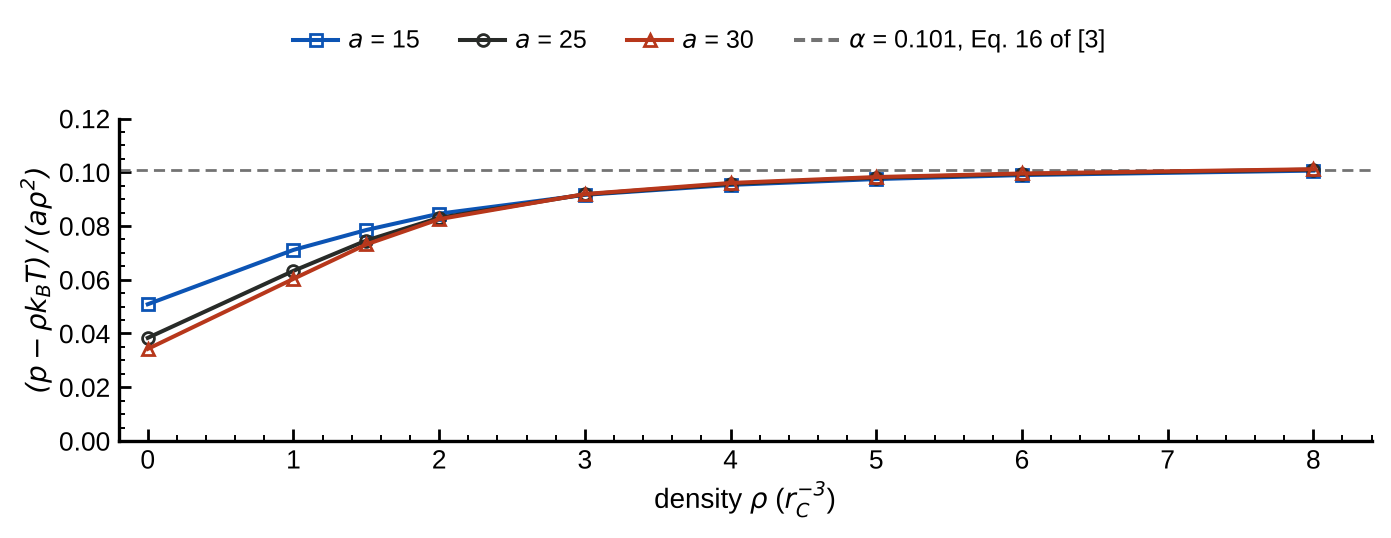

,a = 15,a = 25,a = 30
ρ (r_C⁻³),,,
0.0,0.0509,0.0384,0.0343
1.0,0.0711,0.0633,0.0603
1.5,0.0785,0.0746,0.0732
2.0,0.0846,0.0830,0.0826
3.0,0.0916,0.0918,0.0919
4.0,0.0953,0.0957,0.0960
5.0,0.0975,0.0980,0.0982
6.0,0.0990,0.0993,0.0996
8.0,0.1006,0.1010,0.1012


In [15]:
fig, axes = one_panel()
axes.axhline(0.101, color='0.45', lw=1.0, ls='--')
for column, marker, color in zip(eos.columns, ['s', 'o', '^'], [C['A'], C['ink'], C['B']]):
    axes.plot(eos.index, eos[column], marker=marker, color=color, mfc='none', mew=1.0)
axes.set_xlim(-0.2, 8.4)
axes.set_ylim(0, 0.12)
axes.set_xlabel(r'density $\rho$ ($r_C^{-3}$)')
axes.set_ylabel(r'$(p - \rho k_BT)\,/\,(a \rho^2)$')
top_legend(fig, [Line2D([], [], color=C['A'], marker='s', mfc='none', label='$a$ = 15'),
                 Line2D([], [], color=C['ink'], marker='o', mfc='none', label='$a$ = 25'),
                 Line2D([], [], color=C['B'], marker='^', mfc='none', label='$a$ = 30'),
                 Line2D([], [], color='0.45', ls='--', label=r'$\alpha$ = 0.101, Eq. 16 of [3]')])
fig.savefig(FIGURES / 'equation_of_state.pdf')
plt.show()

eos.round(4)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The repulsion that gives κ<sup>−1</sup> = 16 at ρ = 3, from α of Eq. 16 and from α measured here at ρ = 3:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code computes a<sub>ii</sub> from κ<sup>−1</sup> = 1 + 2αaρ = 16 for both values of α.</div>

In [16]:
alpha_3 = eos.loc[3.0, 'a = 25']
pd.DataFrame({'α': [0.101, alpha_3],
              'a_ii ρ (k_BT), κ⁻¹ = 16': [15 / (2 * 0.101), 15 / (2 * alpha_3)],
              'a_ii at ρ = 3 (k_BT/r_C)': [15 / (2 * 0.101 * 3), 15 / (2 * alpha_3 * 3)]},
             index=['Groot–Warren, Eq. 16', 'this notebook, ρ = 3, a = 25']).round(3)

,α,"a_ii ρ (k_BT), κ⁻¹ = 16",a_ii at ρ = 3 (k_BT/r_C)
"Groot–Warren, Eq. 16",0.101,74.257,24.752
"this notebook, ρ = 3, a = 25",0.092,81.708,27.236


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Low-density limit (Figure 4).** The integral gives 0.0509, 0.0384 and 0.0343 for a = 15, 25 and 30, the values of
  [3].
- **Scaling.** Above ρ ≈ 2 the three repulsions fall on one curve, which levels off toward 0.101 at high density
  (0.101 for a = 25 at ρ = 8). At ρ = 3 it is 0.092, so the measured slope gives a<sub>ii</sub> = 27.2 instead
  of 25: a reminder that a = 25 is a round number from a fit, not an exact match to water.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#795548; color:#ffffff; padding:8px 14px; border-radius:6px;">Structure<br><span style="font-size:0.72em; font-weight:normal;">the radial distribution function, Fig. 2 of [3]</span></h2>

The radial distribution function is the density of beads at a distance r from a bead, divided by the mean density,

$$g(r) = \frac{\langle n(r) \rangle}{4\pi r^2\, \Delta r\, \rho} ,$$

where ⟨n(r)⟩ is the mean number of beads in a shell of width Δr at r [5]. A Lennard-Jones liquid has g(r) = 0 inside
the core and a strong first peak. Groot and Warren show g(r) of the fluid with ρ = 3 and a = 25 in their Fig. 2.

**Figure 5.** Radial distribution function of the DPD fluid (ρ = 3, a = 25), mean over 10 configurations 4 τ apart.
The dashed line marks g(r) = 1. `figures/rdf.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>rdf</code>, averages g(r) over 1000 more steps, draws Figure 5 (<code>figures/rdf.pdf</code>) and gives g(r) at three distances.</div>

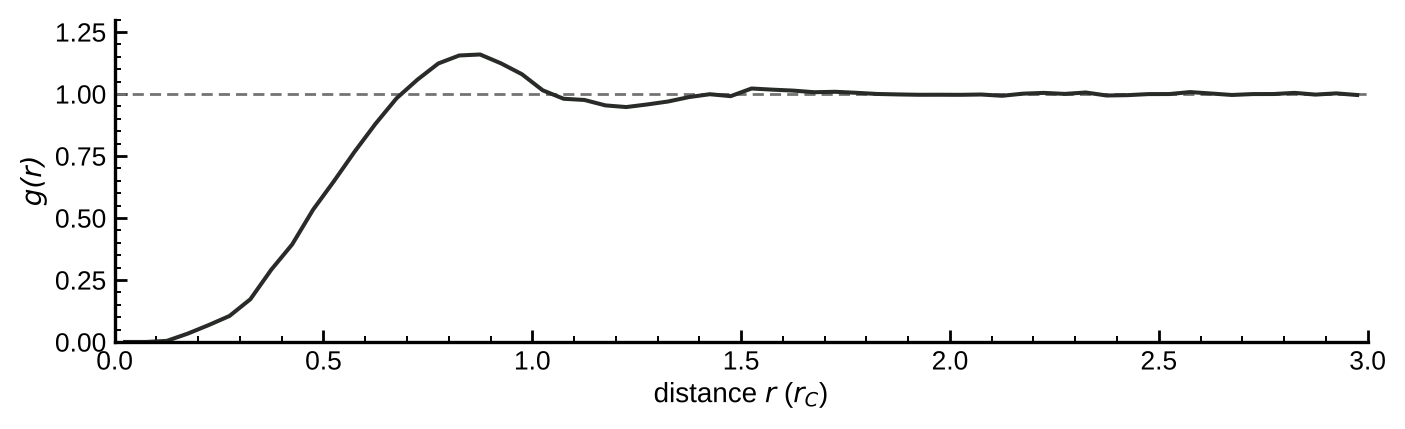

,r (r_C),g(r)
short distance,0.200,0.051
half a cutoff,0.500,0.590
first maximum,0.875,1.159


In [17]:
def rdf(pos, box, bins=60, r_max=3.0):
    """Radial distribution function g(r) of one configuration: bin centers (r_C) and g."""
    wrapped = pos % box
    tree = cKDTree(wrapped, boxsize=box)
    edges = np.linspace(0, r_max, bins + 1)
    cumulative = np.array([tree.count_neighbors(tree, x) for x in edges[1:]], float) - len(wrapped)
    counts = np.diff(np.concatenate([[0.0], cumulative]))         # ordered pairs in each shell, self pairs removed
    shells = 4 / 3 * np.pi * (edges[1:]**3 - edges[:-1]**3)
    g = counts / (len(wrapped) * len(wrapped) / np.prod(box) * shells)
    return 0.5 * (edges[1:] + edges[:-1]), g


snapshots = []


def collect_rdf(step, pos_now, vel_now):
    snapshots.append(rdf(pos_now, box)[1])


pos, vel = run(pos, vel, types, a, box, nsteps=1000, every=100, callback=collect_rdf, seed=7)
r_bins = rdf(pos, box)[0]
g = np.mean(snapshots, axis=0)

fig, axes = one_panel()
axes.axhline(1, color='0.45', lw=1.0, ls='--')
axes.plot(r_bins, g, color=C['ink'])
axes.set_xlim(0, 3)
axes.set_ylim(0, 1.3)
axes.set_xlabel(r'distance $r$ ($r_C$)')
axes.set_ylabel(r'$g(r)$')
fig.savefig(FIGURES / 'rdf.pdf')
plt.show()

peak = np.argmax(g)
pd.DataFrame({'r (r_C)': [0.2, 0.5, r_bins[peak]],
              'g(r)': [np.interp(0.2, r_bins, g), np.interp(0.5, r_bins, g), g[peak]]},
             index=['short distance', 'half a cutoff', 'first maximum']).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Structure (Figure 5).** g(r) is still 0.05 at r = 0.2 r<sub>C</sub> and 0.59 at half a cutoff: beads come much
  closer than in a Lennard-Jones liquid, where g(r) = 0 inside the core. The first maximum is weak (1.16 at r = 0.875 r<sub>C</sub>), and the
  structure is gone after about two cutoffs, as in Fig. 2 of [3]. In the polymer models of [3] and of notebook 03,
  the springs between bonded beads are tuned so that the bonded distance sits near this maximum. Structure on larger
  scales comes from differences between bead types, the subject of notebook 02.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#005F73; color:#ffffff; padding:8px 14px; border-radius:6px;">Diffusion<br><span style="font-size:0.72em; font-weight:normal;">mean squared displacement, the Einstein relation and the Schmidt number</span></h2>

The mean squared displacement (MSD) measures how far the beads move on average,

$$\mathrm{MSD}(t) = \langle |\mathbf{r}_i(t) - \mathbf{r}_i(0)|^2 \rangle .$$

At long times it grows linearly, and the slope gives the self-diffusion coefficient D through the Einstein relation
MSD = 6Dt [5], fitted here for t > 10 τ. Groot and Warren [3] estimated D from the friction alone, by treating one bead
as a Brownian particle in a uniform fluid (their Appendix):

$$D \approx \frac{45\,k_BT}{2\pi\gamma\rho\, r_C^3} .$$

**Figure 6.** Mean squared displacement of the DPD fluid over 60 τ, with the fitted line 6Dt (dashed). `figures/msd.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code runs 1500 more steps, computes the MSD and D, draws Figure 6 (<code>figures/msd.pdf</code>) and compares D with the estimate of [3].</div>

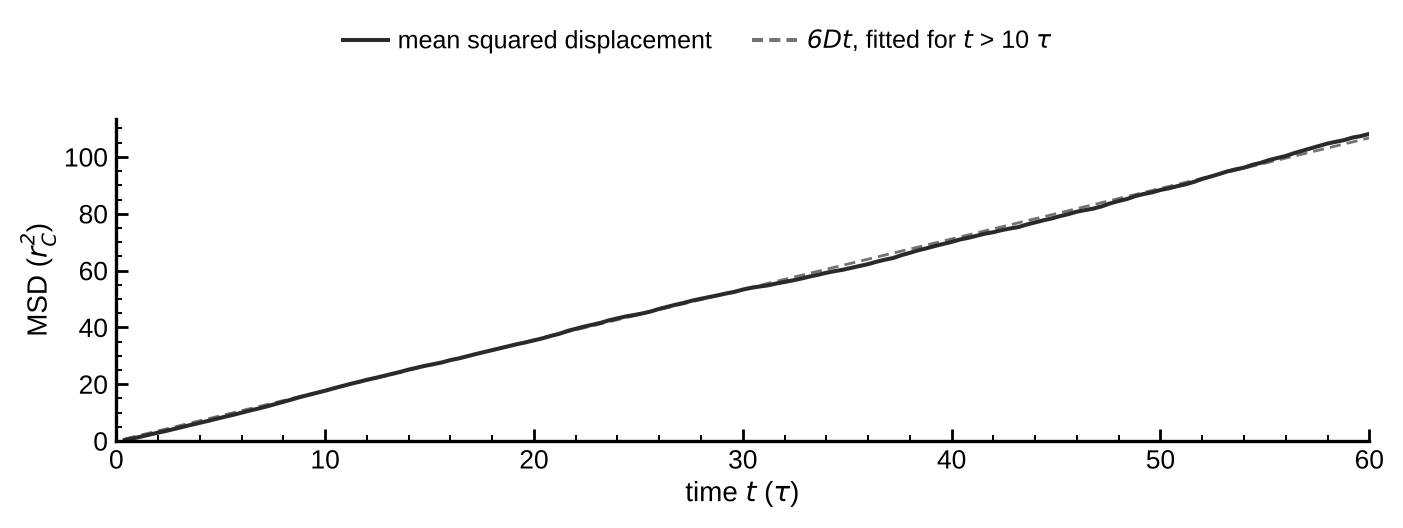

,D (r_C²/τ)
"this notebook, γ = 4.5",0.296
estimate 45 k_BT / (2πγρ) of [3],0.531


In [18]:
reference = pos.copy()
lag, msd = [], []


def track(step, pos_now, vel_now):
    lag.append(step * DT)
    msd.append(np.mean(np.sum((pos_now - reference)**2, axis=1)))


pos, vel = run(pos, vel, types, a, box, nsteps=1500, every=10, callback=track, seed=8)
lag, msd = np.array(lag), np.array(msd)
fit = lag > 10
D = np.polyfit(lag[fit], msd[fit], 1)[0] / 6
D_theory = 45 / (2 * np.pi * GAMMA * rho)

fig, axes = one_panel()
axes.plot(lag, 6 * D * lag, color='0.45', lw=1.0, ls='--')
axes.plot(lag, msd, color=C['ink'])
axes.set_xlim(0, lag[-1])
axes.set_ylim(0, None)
axes.set_xlabel(r'time $t$ ($\tau$)')
axes.set_ylabel(r'MSD ($r_C^2$)')
top_legend(fig, [Line2D([], [], color=C['ink'], label='mean squared displacement'),
                 Line2D([], [], color='0.45', ls='--', label=r'$6Dt$, fitted for $t$ > 10 $\tau$')])
fig.savefig(FIGURES / 'msd.pdf')
plt.show()

pd.DataFrame({'D (r_C²/τ)': [D, D_theory]},
             index=['this notebook, γ = 4.5', 'estimate 45 k_BT / (2πγρ) of [3]']).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Diffusion (Figure 6).** D = 0.30 r<sub>C</sub>²/τ, against 0.53 from the estimate. The estimate leaves out
  the conservative force, which hinders the motion at this density; Groot and Warren found D = 0.306 against 0.354
  from the estimate at γ = 6.75 [3]. Exercise 2 varies γ.
- **Schmidt number.** The ratio of momentum transport to particle transport, Sc = ν/D (ν the kinematic viscosity),
  is of order 1000 for water but about 1 for the standard DPD fluid (Sc = 1.00 at γ = 6.75 in [3]): beads diffuse
  about as fast as momentum spreads. This is a price of the soft potential. Equilibrium structures are the strength of
  DPD; its dynamics need care when compared with real time scales.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6D597A; color:#ffffff; padding:8px 14px; border-radius:6px;">Exercises<br><span style="font-size:0.72em; font-weight:normal;">fluctuation–dissipation, friction and compressibility, with solutions</span></h2>

Each exercise has its solution in the cells below it.

**Exercise 1. The fluctuation–dissipation theorem.** Run the fluid with w<sup>D</sup> = w<sup>R</sup> = 1 − r, the
form used by Hoogerbrugge and Koelman [1], and keep ζ² = 2γk<sub>B</sub>T. Which temperature does the fluid reach?
A rough estimate balances the heating by the noise, proportional to ζ²∫(w<sup>R</sup>)² r² dr, against the cooling by
the friction, proportional to 2γk<sub>B</sub>T∫w<sup>D</sup> r² dr.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 1) measures k<sub>B</sub>T with both choices of w<sup>D</sup>.</div>

In [19]:
# Solution 1
results = []
for power, label in [(2, 'w^D = (w^R)², Eq. 5 of [3]'), (1, 'w^D = w^R')]:
    values = []

    def collect_temperature(step, pos_now, vel_now):
        if step > 500:
            values.append(temperature(vel_now))

    run(pos, vel, types, a, box, 1500, wd_power=power, every=10, callback=collect_temperature, seed=9)
    results.append({'weight functions': label, 'k_BT': np.mean(values)})

# the balance of heating and cooling, without and with the measured g(r) of Figure 5
inside = r_bins < 1
weight_r = 1 - r_bins[inside]
shell = r_bins[inside]**2
estimate_flat = np.sum(weight_r**2 * shell) / np.sum(weight_r * shell)
estimate_g = np.sum(weight_r**2 * g[inside] * shell) / np.sum(weight_r * g[inside] * shell)
print(f'estimate with g(r) = 1: k_BT = {estimate_flat:.3f}; with the measured g(r): k_BT = {estimate_g:.3f}')
pd.DataFrame(results).set_index('weight functions').round(3)

estimate with g(r) = 1: k_BT = 0.400; with the measured g(r): k_BT = 0.307


,k_BT
weight functions,
"w^D = (w^R)², Eq. 5 of [3]",1.019
w^D = w^R,0.258


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 1.** With w<sup>D</sup> = w<sup>R</sup> the fluid settles at k<sub>B</sub>T = 0.26, against 1.02
  with w<sup>D</sup> = (w<sup>R</sup>)². With g(r) = 1 the estimate gives (1/30)/(1/12) = 0.4: the friction acts
  more strongly at large r than the noise, so the fluid is colder than ζ²/2γ. Weighted with the measured g(r), which
  removes pairs at short distance where the two weights are close, the estimate drops to 0.31, closer to the measured
  value; the rest is beyond the simple form of the estimate. The steady state still exists, but its temperature is not
  the one put into the noise, and in general it need not be a Boltzmann distribution at all [2, 3].

**Exercise 2. Friction and diffusion.** Measure D for γ = 1.5, 4.5, 9 and 18 at k<sub>B</sub>T = 1 (ζ follows from
the fluctuation–dissipation theorem; γ = 18 uses Δt = 0.02 τ). Compare with 45k<sub>B</sub>T/(2πγρ). Does the
temperature change?

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 2) measures D and the mean temperature for four values of γ.</div>

In [20]:
# Solution 2
rows = []
for gamma in [1.5, 4.5, 9.0, 18.0]:
    start_pos, lag2, msd2, values = pos.copy(), [], [], []

    def collect(step, pos_now, vel_now):
        lag2.append(step * DT)
        msd2.append(np.mean(np.sum((pos_now - start_pos)**2, axis=1)))
        values.append(temperature(vel_now))

    run(pos, vel, types, a, box, 1000, dt=0.02 if gamma > 10 else DT, gamma=gamma, every=10, callback=collect,
        seed=10)
    lag2, msd2 = np.array(lag2), np.array(msd2)
    D_gamma = np.polyfit(lag2[lag2 > lag2[-1] / 3], msd2[lag2 > lag2[-1] / 3], 1)[0] / 6
    rows.append({'γ': gamma, 'D (r_C²/τ)': D_gamma, '45 k_BT / (2πγρ)': 45 / (2 * np.pi * gamma * rho),
                 'k_BT': np.mean(values)})
pd.DataFrame(rows).set_index('γ').round(3)

,D (r_C²/τ),45 k_BT / (2πγρ),k_BT
γ,,,
1.5,0.316,1.592,1.019
4.5,0.298,0.531,1.022
9.0,0.272,0.265,1.042
18.0,0.110,0.133,1.022


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 2.** D falls from 0.32 to 0.11 when γ grows from 1.5 to 18, much less than the factor of 12 of the
  estimate. At small γ the conservative repulsion of the neighbors, not the friction, limits the motion, and the
  estimate is far too high; from γ ≈ 9 on the two are close (0.27 against 0.27 at γ = 9, 0.11 against 0.13 at
  γ = 18). The temperature stays close to 1
  (1.02 to 1.04), since the noise grows with γ through ζ² = 2γk<sub>B</sub>T. Equilibrium properties do not depend on
  γ; only the dynamics do, which [3] suggested as a way to raise the Schmidt number.

**Exercise 3. Compressibility at another density.** Groot and Warren used a = 15 at ρ = 5 (a = 75/ρ). Measure the
pressure at ρ = 4.8 and 5.2 with a = 15, compute κ<sup>−1</sup> = (1/k<sub>B</sub>T) ∂p/∂ρ by a finite difference,
and compare with water.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 3) measures κ<sup>−1</sup> at ρ = 5 and a = 15.</div>

In [21]:
# Solution 3
rho_5, a_5, step_rho = 5.0, 15.0, 0.2
pressures = []
for rho_n in [rho_5 - step_rho, rho_5 + step_rho]:
    excess = excess_pressure(rho_n, a_5, nsteps=800, seed=11)
    pressures.append(rho_n + excess * a_5 * rho_n**2)              # k_BT = 1
inverse_compressibility = (pressures[1] - pressures[0]) / (2 * step_rho)
pd.DataFrame({'κ⁻¹': [inverse_compressibility, 1 + 2 * 0.101 * a_5 * rho_5, 15.98]},
             index=['this notebook, ρ = 5, a = 15', 'Eq. 16 of [3], ρ = 5, a = 15', 'water at 300 K [3]']).round(2)

,κ⁻¹
"this notebook, ρ = 5, a = 15",16.36
"Eq. 16 of [3], ρ = 5, a = 15",16.15
water at 300 K [3],15.98


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 3.** κ<sup>−1</sup> = 16.4, against 16.15 from Eq. 16 of [3] and 15.98 for water: the rule
  a<sub>ii</sub> = 75 k<sub>B</sub>T/ρ keeps the compressibility of water at other densities. The finite difference is
  noisy, since it divides a small pressure difference by 0.4.

Notebook 02 adds a second bead type and connects the repulsion a<sub>ij</sub> to the Flory–Huggins parameter χ. It
uses the same force code, with harmonic springs added for chains.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#37474F; color:#ffffff; padding:8px 14px; border-radius:6px;">Summary<br><span style="font-size:0.72em; font-weight:normal;">the answers to the four questions</span></h2>

1. **Temperature and time step.** With Δt = 0.04 τ the thermostat holds k<sub>B</sub>T at 1.025 (ρ = 3); the
   error grows with Δt (2.6 and 3.8 % at 0.04 and 0.05 τ for ρ = 4, against 2 and 3 % in [3]), is smaller
   with λ = 0.65, and is much larger with the Euler scheme.
2. **Equation of state.** Above ρ ≈ 2, (p − ρk<sub>B</sub>T)/(aρ²) is the same for a = 15, 25 and 30 and approaches
   α = 0.101; at ρ = 3 it is 0.092, so the pressure of the standard fluid is 23.7 against 25.7 from Eq. 16 of
   [3]. κ<sup>−1</sup> ≈ 16, the value of water, needs aρ ≈ 75 k<sub>B</sub>T, which gives a<sub>ii</sub> = 25 at
   ρ = 3.
3. **Structure.** The DPD fluid has a weak first maximum of g(r) (1.16 at 0.875 r<sub>C</sub>), no structure
   beyond about two cutoffs, and beads overlap.
4. **Diffusion.** D = 0.30 r<sub>C</sub>²/τ at γ = 4.5, below the estimate 0.53 of [3], which leaves out the
   conservative force; the Schmidt number of DPD is about 1, against about 1000 for water.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">References<br><span style="font-size:0.72em; font-weight:normal;">the theory of DPD</span></h2>

1. P. J. Hoogerbrugge and J. M. V. A. Koelman, *Europhys. Lett.* **19**, 155–160 (1992).
2. P. Español and P. Warren, *Europhys. Lett.* **30**, 191–196 (1995).
3. R. D. Groot and P. B. Warren, *J. Chem. Phys.* **107**, 4423–4435 (1997), https://doi.org/10.1063/1.474784.
4. K. Hasheminejad, *Computational modelling of block copolymer surface coatings at multiple length scales*, doctoral thesis (2026), http://urn.fi/URN:ISBN:978-952-64-2955-7.
5. M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed. (Oxford University Press, 2017).
6. A. Scacchi, K. Hasheminejad, S. Javan Nikkhah and M. Sammalkorpi, *J. Colloid Interface Sci.* **640**, 809–819 (2023).
7. K. Hasheminejad et al., *Appl. Surf. Sci.* **640**, 158324 (2023).

</div>